In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
np.random.seed(1)
X = np.random.rand(50,1)
y = 0.7*(X**5) - \
    2.1*(X**4) + \
    2.7*(X**3) + \
    3.5*(X**2) + \
    0.3* X + \
    0.4*np.random.rand(50,1)

In [ ]:
X.shape, y.shape

((50, 1), (50, 1))

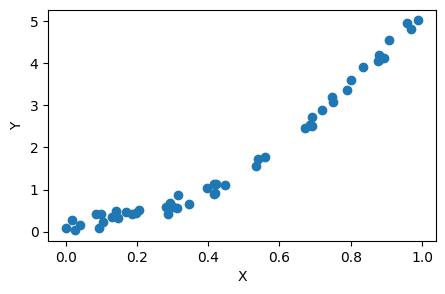

In [ ]:
fig = plt.figure(figsize=(5,3))
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

Adj. R-score 0.9332371047707784


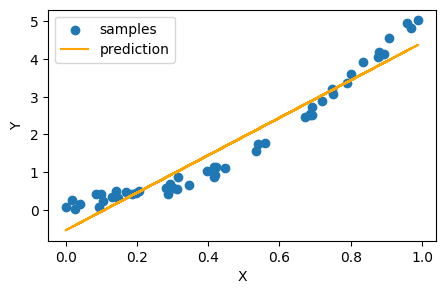

In [ ]:
def adj_r(r_sq,X,Y):
  adj_r1 = (1 - ((1-r_sq)*(len(Y)-1))/(len(Y)-X.shape[1]-1) )
  return adj_r1

def r2_score(y,y_):
    num = np.sum((y-y_)**2)
    denom = np.sum((y- y.mean())**2)
    score = (1- num/denom)
    return score

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

output = model.predict(X)

print('Adj. R-score', adj_r(r2_score(y, output), X, y))

fig = plt.figure(figsize=(5,3))
plt.scatter(X, y, label="samples")
plt.plot(X, output, label="prediction",color='orange')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

Adj. R-score 0.9947910474710182


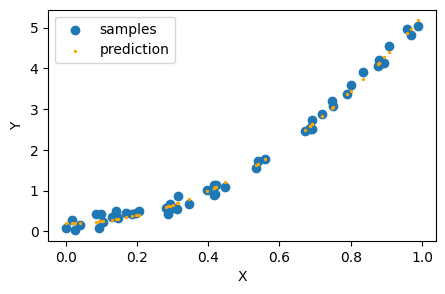

In [ ]:
X_deg2 = np.hstack([X, X**2])

model_deg2 = LinearRegression()
model_deg2.fit(X_deg2, y)
output = model_deg2.predict(X_deg2)
print('Adj. R-score', adj_r(r2_score(y, output), X, y))

fig = plt.figure(figsize=(5,3))
plt.scatter(X, y, label="samples")
plt.scatter(X, output, label="prediction",color='orange', s=2)
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [ ]:
X_deg2[:5]

array([[4.17022005e-01, 1.73907352e-01],
       [7.20324493e-01, 5.18867376e-01],
       [1.14374817e-04, 1.30815988e-08],
       [3.02332573e-01, 9.14049845e-02],
       [1.46755891e-01, 2.15372915e-02]])

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler


Adj. R-score Degree 1 = 0.9332371047707784


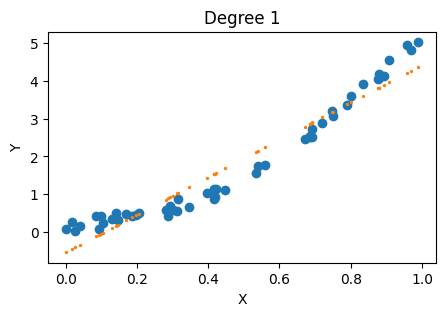

Adj. R-score Degree 2 = 0.9947910474710182


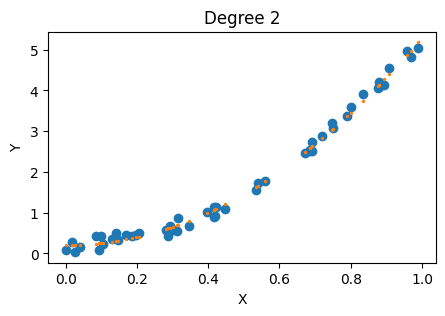

Adj. R-score Degree 3 = 0.9948189561660776


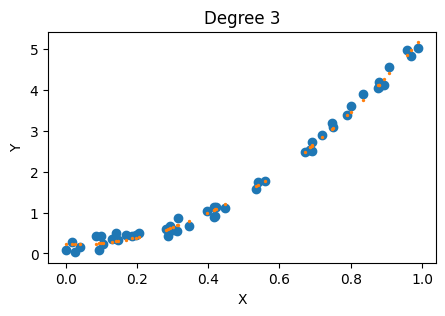

Adj. R-score Degree 4 = 0.9958723656752901


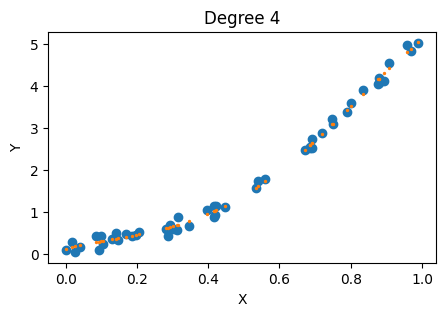

Adj. R-score Degree 5 = 0.9959170101989778


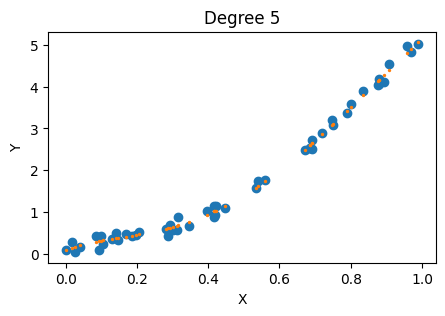

Adj. R-score Degree 6 = 0.9959321057310005


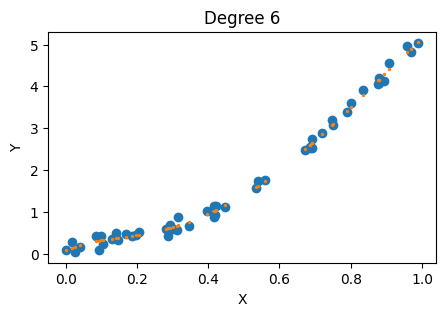

Adj. R-score Degree 7 = 0.9959505944841461


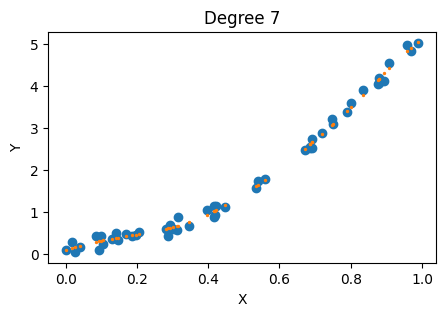

Adj. R-score Degree 8 = 0.9959999445673192


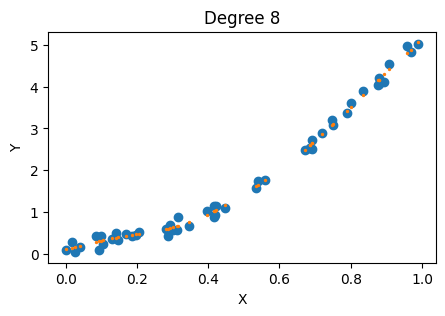

Adj. R-score Degree 9 = 0.9960515584977236


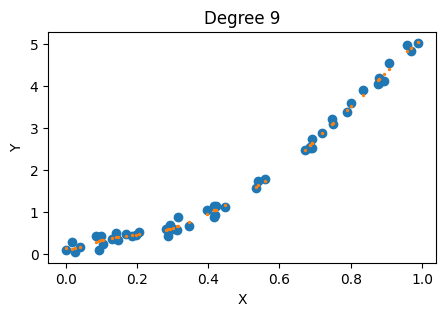

Adj. R-score Degree 10 = 0.9962099180383119


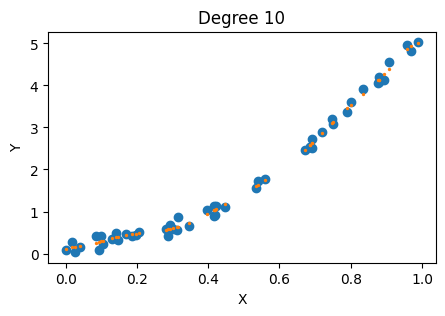

In [ ]:
for i in range(1, 11):

  #creating a polynomial feature
  poly = PolynomialFeatures(degree=i)
  X_poly = poly.fit_transform(X)

  #scaling the polynomial features
  scaler = StandardScaler()
  X_poly_scaled = scaler.fit_transform(X_poly)

  #training the model
  model = LinearRegression()
  model.fit(X_poly_scaled, y)


  #prediction
  output = model.predict(X_poly_scaled)

  #print adj.r2-score
  print('Adj. R-score', 'Degree', i, '=', adj_r(r2_score(y, output), X, y))
  fig = plt.figure(figsize=(5,3))
  plt.scatter(X, y, label="samples")
  plt.scatter(X, output, label="prediction", s=2)
  plt.xlabel("X")
  plt.ylabel("Y")
  plt.title(f"Degree {i}")
  plt.show()

In [ ]:
# Underfit, Overfit

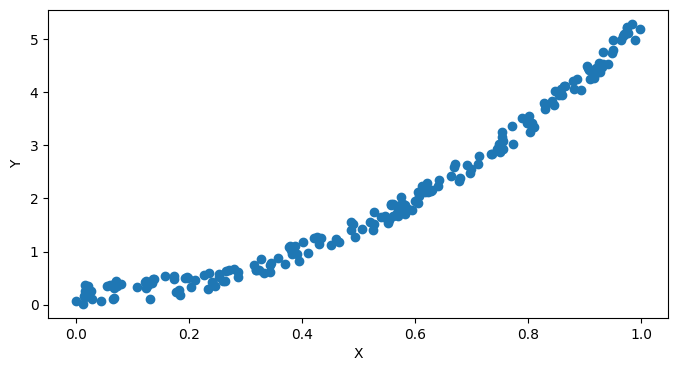

In [ ]:
X = np.random.rand(200,1)
y = 0.7*(X**5) - \
    2.1*(X**4) + \
    2.7*(X**3) + \
    3.5*(X**2) + \
    0.3* X + \
    0.4*np.random.rand(200,1)

plt.figure(figsize=(8,4))
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [ ]:
def adj_r(r_sq,X,Y):
  adj_r1 = (1 - ((1-r_sq)*(len(Y)-1))/(len(Y)-X.shape[1]-1) )
  return adj_r1

In [ ]:
degrees = 30 # number of data-points
train_scores = []
test_scores = []

for d in range(1, degrees):

    #creates polynomial feature
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X_train)
    X_test_poly = poly.fit_transform(X_test)

    #Standardization
    scaler = StandardScaler()
    X_poly_scaled = scaler.fit_transform(X_poly)
    X_test_poly_scaled = scaler.transform(X_test_poly)

    #training model
    model = LinearRegression()
    model.fit(X_poly_scaled, y_train)

    #Calculating Performance
    adjr2_train = adj_r(model.score(X_poly_scaled, y_train), X_poly_scaled, y_train)
    adjr2_test = adj_r(model.score(X_test_poly_scaled, y_test), X_test_poly_scaled, y_test)

    train_scores.append(adjr2_train)
    test_scores.append(adjr2_test)

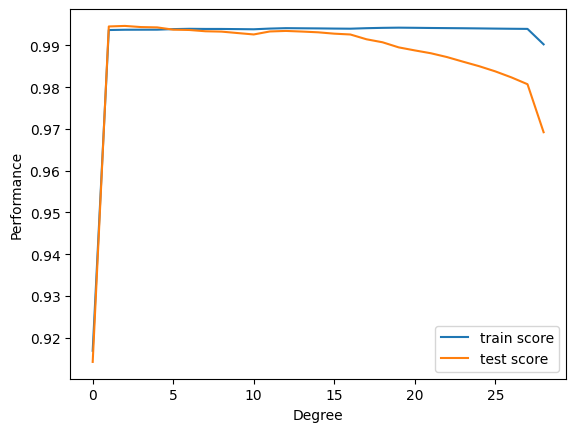

In [ ]:
plt.plot(train_scores, label='train score')
plt.plot(test_scores, label = 'test score')
plt.xlabel('Degree')
plt.ylabel("Performance")
plt.legend()
plt.show()

In [ ]:
np.argmax(test_scores)

2

In [ ]:
test_scores[:5]

[0.9141802361419464,
 0.9945487135377171,
 0.9946787900676096,
 0.9944029592062222,
 0.9943266722534333]